In [1]:
import pandas as pd
from h3 import h3
import glob
import numpy as np
from pandas import merge
import json
import geopandas as gpd
import matplotlib.pyplot as plt
from shapely.geometry import shape
from datetime import datetime, timedelta
import seaborn as sns

In [2]:
# Pandas Config
pd.set_option('display.max_columns', None)
pd.options.display.max_rows = 200

# ShareNow Data 
VEHICLE_TRIP = '/Users/demircanm/sciebo/IS3/Research_Projects/EmpiricalAnalysisSharedMobility/02_Data/final_dataset.csv'

# TIMEZONE
TIMEZONE = 'Europe/Berlin'


In [3]:
# Read Trips
trips = pd.read_csv(VEHICLE_TRIP)

/Users/demircanm/opt/anaconda3/envs/SharedMobility/lib/python3.7/site-packages/IPython/core/interactiveshell.py:3146: DtypeWarning: Columns (4,21,22,114) have mixed types.Specify dtype option on import or set low_memory=False.
  interactivity=interactivity, compiler=compiler, result=result)


In [4]:
# Remove Bike Trips
trips = trips[(trips["vehicleType"] != "bicycle") & (trips["vehicleType"] != "bycicle")]


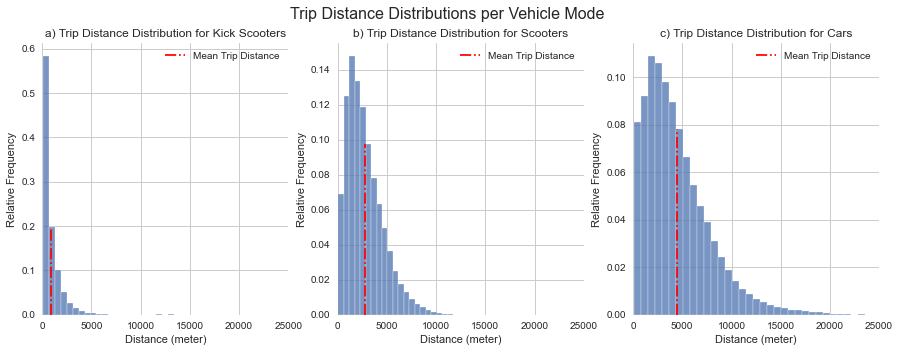

In [278]:
# Visualize Trip Characteristics 
import seaborn as sns

fig, (ax1, ax2, ax3) = plt.subplots(nrows=1, ncols=3, figsize=(15, 5))
fig.suptitle('Trip Distance Distributions per Vehicle Mode', fontsize=16, y=0.98)

sns.histplot(trips[(trips["vehicleType"] == "kick scooter")], x="distance", bins = 40, stat="probability", multiple="stack", ax= ax1)
ax1.set_xlim(0, 25000)
ax1.set_xlabel("Distance (meter)")
ax1.set_ylabel("Relative Frequency")

ax1.set_title("a) Trip Distance Distribution for Kick Scooters", fontsize=12)

# Mean Value
ax1.axvline(x=trips[(trips["vehicleType"] == "kick scooter")]["distance"].mean(), ymin = 0.0, ymax = 0.32, color='red', linestyle='-.', label='Mean Trip Distance')

sns.histplot(trips[(trips["vehicleType"] == "scooter")], x="distance", bins = 40, stat="probability", multiple="stack", ax= ax2)
ax2.set_xlim(0, 25000)
ax2.set_xlabel("Distance (meter)")
ax2.set_ylabel("Relative Frequency")

ax2.set_title("b) Trip Distance Distribution for Scooters")

# Mean Value
ax2.axvline(x=trips[(trips["vehicleType"] == "scooter")]["distance"].mean(), ymin = 0.0, ymax = 0.63, color='red', linestyle='-.', label='Mean Trip Distance')

sns.histplot(trips[(trips["vehicleType"] == "car")], x="distance", bins = 40, stat="probability", multiple="stack", ax= ax3)
ax3.set_xlim(0, 25000)
ax3.set_xlabel("Distance (meter)")
ax3.set_ylabel("Relative Frequency")

ax3.set_title("c) Trip Distance Distribution for Cars")


# Mean Value
ax3.axvline(x=trips[(trips["vehicleType"] == "car")]["distance"].mean(), ymin = 0.0, ymax = 0.685, color='red', linestyle='-.', label='Mean Trip Distance')


# Legends
ax1.legend()
ax2.legend()
ax3.legend()

# Slice list to remove first handle
# plt.legend(handles = handles[0:], labels = labels)

plt.savefig('trip_distributions.pdf')

# plt.show()

In [7]:
# Sample 

ks_samples = trips[(trips["vehicleType"] == "kick scooter")].sample(100000)
scooter_samples = trips[(trips["vehicleType"] == "scooter")].sample(100000)
car_samples = trips[(trips["vehicleType"] == "car")].sample(100000)

## Scooter vs. Car Mode Choice

In [8]:
# Sample Car and Scooter Trips
scooter_samples = trips[(trips["vehicleType"] == "scooter")].sample(100000)
car_samples = trips[(trips["vehicleType"] == "car")].sample(100000)

In [9]:
# Concat Sampled Trips
trip_sampled = pd.concat([scooter_samples, car_samples])

In [10]:
# https://www.statsmodels.org/stable/discretemod.html 
import statsmodels.api as sm

X = sm.add_constant(trip_sampled["distance"])
Y = trip_sampled["vehicleType"]
mnl_model = sm.MNLogit(Y, X).fit()

# spector_data = sm.datasets.spector.load_pandas()

Optimization terminated successfully.
         Current function value: 0.644913
         Iterations 5


In [11]:
# Print Choice Model Summary
mnl_model.summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                          MNLogit Regression Results                          
==============================================================================
Dep. Variable:            vehicleType   No. Observations:               200000
Model:                        MNLogit   Df Residuals:                   199998
Method:                           MLE   Df Model:                            1
Date:                Mon, 18 Oct 2021   Pseudo R-squ.:                 0.06959
Time:                        10:52:04   Log-Likelihood:            -1.2898e+05
converged:                       True   LL-Null:                   -1.3863e+05
Covariance Type:            nonrobust   LLR p-value:                     0.000
=======================================================================================
vehicleType=scooter       coef    std err          z      P>|z|      [0.025      0.975]
---------------------------------------------------------------------------------------
const                   0.8841      0.008    107.255      0.000       0.868       0.900
distance               -0.0003   2.05e-06   -123.815      0.000      -0.000      -0.000
=======================================================================================
"""

In [12]:
# Predict Outcome based on Distance 
mnl_model.predict(X)

,0,1
2008966,0.317776,0.682224
2030087,0.348191,0.651809
1951435,0.488099,0.511901
2608473,0.490280,0.509720
1979734,0.382228,0.617772
...,...,...
415912,0.618241,0.381759
2417333,0.461644,0.538356
2593120,0.581954,0.418046
696741,0.549201,0.450799


In [14]:
# We generate test data from 0 meter to 10.000 meter and visualize the 
# probability densities

distance      = list(range(1,15000))
visualization = pd.DataFrame(distance, columns = ["distance"])
visualization = sm.add_constant(visualization)

# Predict Outcome
result = mnl_model.predict(visualization)

# Rename Columns 
result.columns = ["car", "scooter"]

# Copy Distance Columns
result["distance"] = visualization["distance"]

In [129]:
import matplotlib.transforms as mtrans
from matplotlib.text import TextPath
from matplotlib.patches import PathPatch

# Curly Bracket 
def curly(x,y, scale, ax=None):
    if not ax: ax=plt.gca()
    tp = TextPath((0, 0), "}", size=1)
    trans = mtrans.Affine2D().scale(1, scale) + \
        mtrans.Affine2D().translate(x,y) + ax.transData
    pp = PathPatch(tp, lw=0, fc="k", transform=trans)
    ax.add_artist(pp)

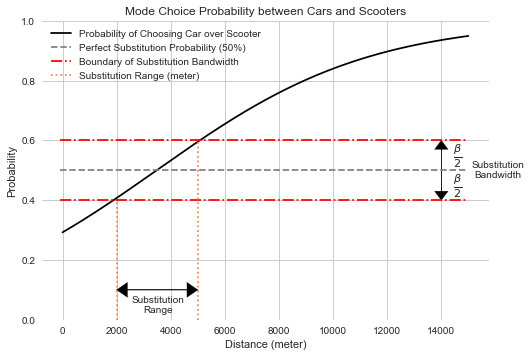

In [236]:
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
plt.style.use("seaborn")

sns.set_style("whitegrid")

f, ax = plt.subplots(1)

colors = ["#0b559f", "#bad6eb"]
# colors = sns.color_palette("Blues", 2)
labels=["Car", "Scooter"]
# fix, ax = plt.stackplot(result["distance"], result["car"], result["scooter"], labels=labels, colors=colors)

ax = sns.lineplot(data=result, x="distance", y="car", ax = ax, color="black", label='Probability of Choosing Car over Scooter') 

# Set Probability Limits
ax.set_ylim(0, 1)

ax.set_title('Mode Choice Probability between Cars and Scooters')

ax.set_ylabel("Probability")

ax.set_xlabel("Distance (meter)")

ax.axhline(y=0.5, xmin = 0.04, xmax = 0.95, color='gray', linestyle='--', label='Perfect Substitution')

ax.axhline(y=0.60, xmin = 0.04, xmax = 0.95, color='r', linestyle='-.', label='Substitution Bandwidth')
ax.axhline(y=0.40, xmin = 0.04, xmax = 0.95, color='r', linestyle='-.')

ax.axvline(x=2000, ymin = 0.00, ymax = 0.4, color='coral', linestyle=':', label='Substitution Range (meter)')
ax.axvline(x=5000, ymin = 0.00, ymax = 0.6, color='coral', linestyle=':')


# Bandwidth Arcs
ax.arrow(14000, 0.4, 0, 0.2, color='black', head_length = 0.03, head_width = 500, length_includes_head = True)
ax.arrow(14000, 0.6, 0, -0.2, color='black', head_length = 0.03, head_width = 500, length_includes_head = True)

# Sub. Range 
ax.arrow(2000, 0.1, 3000, 0, color='black', head_length = 400, head_width = 0.05, length_includes_head = True)
ax.arrow(5000, 0.1, -3000, 0, color='black', head_length = 400, head_width = 0.05, length_includes_head = True)


ax.text(0.93,0.45,r'$ \frac{\beta}{2} $',horizontalalignment='center',
     verticalalignment='center', transform = ax.transAxes, fontsize=16)

ax.text(0.93,0.55,r'$ \frac{\beta}{2} $',horizontalalignment='center',
     verticalalignment='center', transform = ax.transAxes, fontsize=16)

ax.text(0.26,0.05,'Substitution\nRange',horizontalalignment='center',
     verticalalignment='center', transform = ax.transAxes, fontsize=10)


ax.text(1.02,0.5,'Substitution\nBandwidth',horizontalalignment='center',
     verticalalignment='center', transform = ax.transAxes, fontsize=10)


labels = ["Probability of Choosing Car over Scooter", "Perfect Substitution Probability (50%)",'Boundary of Substitution Bandwidth', 'Substitution Range (meter)']
handles, _ = ax.get_legend_handles_labels()

# Slice list to remove first handle
plt.legend(handles = handles[0:], labels = labels)

plt.savefig('mode_choice.pdf')
